# House Price Prediction: линейные модели

Предсказание цены продажи жилья по описанию дома (набор данных Ames Housing, ~2 900 объектов, 80 признаков).

**Что делаем:**
- разбираем данные и подбираем метрику, которая подходит для цен;
- пишем свои препроцессоры и модели с интерфейсом `fit` / `predict` в стиле scikit-learn;
- шаг за шагом улучшаем качество (feature engineering, логарифм таргета, категориальные признаки) и проверяем каждый шаг кросс-валидацией;
- реализуем линейную регрессию с нуля (мини-батч SGD) и сверяем её с `Ridge`;
- собираем итоговый `Pipeline` и подбираем регуляризацию.

## 1. Импорты и настройки

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, make_scorer
from sklearn.pipeline import Pipeline

SEED = 24
TARGET = "Sale_Price"
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 2. Данные

Файл с данными в репозиторий не включён (см. README). Положите его в `data/ames_housing.csv`.

In [2]:
# keep_default_na=False: строка "None" в некоторых колонках означает «нет» (например, нет облицовки),
# а не пропуск, и pandas по умолчанию превратил бы её в NaN
data = pd.read_csv("data/ames_housing.csv", keep_default_na=False)
print(f"Размер: {data.shape}")
data.head()

Размер: (2930, 81)


,MS_SubClass,MS_Zoning,Lot_Frontage,Lot_Area,Street,Alley,Lot_Shape,Land_Contour,Utilities,Lot_Config,...,Fence,Misc_Feature,Misc_Val,Mo_Sold,Year_Sold,Sale_Type,Sale_Condition,Sale_Price,Longitude,Latitude
0,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,141,31770,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,...,No_Fence,None,0,5,2010,WD,Normal,215000,-93.619754,42.054035
1,One_Story_1946_and_Newer_All_Styles,Residential_High_Density,80,11622,Pave,No_Alley_Access,Regular,Lvl,AllPub,Inside,...,Minimum_Privacy,None,0,6,2010,WD,Normal,105000,-93.619756,42.053014
2,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,81,14267,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,...,No_Fence,Gar2,12500,6,2010,WD,Normal,172000,-93.619387,42.052659
3,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,93,11160,Pave,No_Alley_Access,Regular,Lvl,AllPub,Corner,...,No_Fence,None,0,4,2010,WD,Normal,244000,-93.617320,42.051245
4,Two_Story_1946_and_Newer,Residential_Low_Density,74,13830,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Inside,...,Minimum_Privacy,None,0,3,2010,WD,Normal,189900,-93.638933,42.060899


In [3]:
num_cols = data.select_dtypes("number").columns.drop(TARGET)
cat_cols = data.select_dtypes(exclude="number").columns
print(f"Числовых признаков: {len(num_cols)}, категориальных: {len(cat_cols)}")
print(f"Явных пропусков (NaN): {data.isna().sum().sum()}")

Числовых признаков: 34, категориальных: 46
Явных пропусков (NaN): 0


## 3. Разведочный анализ

### 3.1 Целевая переменная

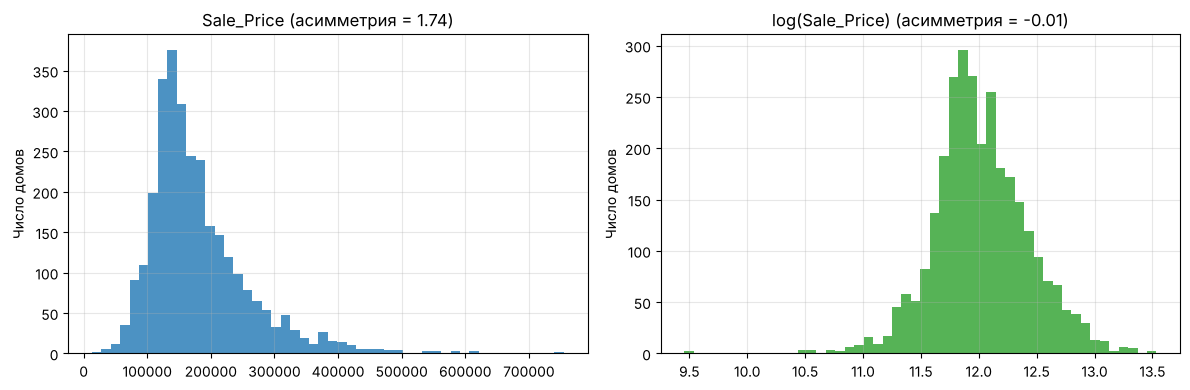

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(data[TARGET], bins=50, color="tab:blue", alpha=0.8)
axes[0].set_title(f"Sale_Price (асимметрия = {data[TARGET].skew():.2f})")
axes[1].hist(np.log(data[TARGET]), bins=50, color="tab:green", alpha=0.8)
axes[1].set_title(f"log(Sale_Price) (асимметрия = {np.log(data[TARGET]).skew():.2f})")
for ax in axes:
    ax.set_ylabel("Число домов")
plt.tight_layout()
plt.show()

Цены сильно скошены вправо, а логарифм цены близок к нормальному распределению. Это хороший аргумент в пользу того, чтобы обучать линейную модель на `log(price)`. Ниже проверим это экспериментально.

### 3.2 Скрытые пропуски и связь признаков с ценой

In [5]:
zero_frontage = (data["Lot_Frontage"] == 0).sum()
print(f"Lot_Frontage == 0: {zero_frontage} домов ({zero_frontage / len(data):.1%})")

Lot_Frontage == 0: 490 домов (16.7%)


Ширина фасада равна нулю у заметной доли домов. Физически это невозможно, то есть нули здесь означают пропуски. Заменим их медианой, когда будем делать предобработку.

In [6]:
corr = data[num_cols].corrwith(np.log(data[TARGET])).sort_values(ascending=False)
print("Топ-10 числовых признаков по корреляции с log(Sale_Price):")
print(corr.head(10).round(3).to_string())

Топ-10 числовых признаков по корреляции с log(Sale_Price):
Gr_Liv_Area       0.696
Garage_Cars       0.675
Garage_Area       0.651
Total_Bsmt_SF     0.626
Year_Built        0.615
First_Flr_SF      0.603
Year_Remod_Add    0.586
Full_Bath         0.577
TotRms_AbvGrd     0.493
Fireplaces        0.489


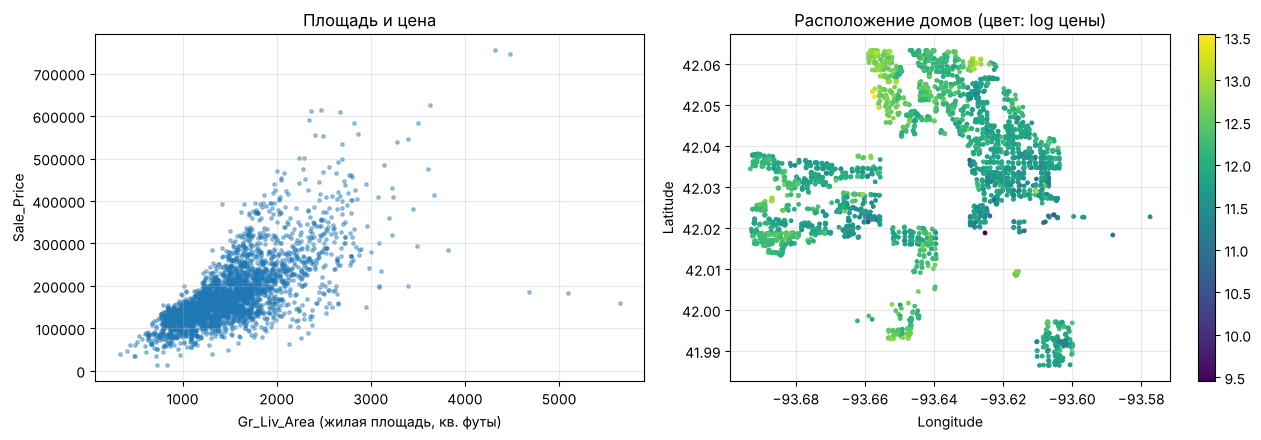

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].scatter(data["Gr_Liv_Area"], data[TARGET], s=6, alpha=0.4)
axes[0].set_xlabel("Gr_Liv_Area (жилая площадь, кв. футы)")
axes[0].set_ylabel("Sale_Price")
axes[0].set_title("Площадь и цена")

sc = axes[1].scatter(data["Longitude"], data["Latitude"], c=np.log(data[TARGET]), s=6, cmap="viridis")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].set_title("Расположение домов (цвет: log цены)")
plt.colorbar(sc, ax=axes[1])
plt.tight_layout()
plt.show()

Площадь сильно связана с ценой. Координаты сами по себе линейной модели почти ничего не дают, но по карте видно, что цена зависит от положения относительно центра города. Из координат можно сделать признак «расстояние до центра».

## 4. Разбиение данных

In [8]:
X = data.drop(columns=TARGET)
y = data[TARGET].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (2344, 80), Test: (586, 80)


## 5. Метрика

MAE понятна, но плохо подходит для цен: ошибка в 10 000 $ для дома за 100 000 $ существенно хуже, чем для дома за 700 000 $. Поэтому основная метрика здесь RMSLE (корень из среднего квадрата ошибки в логарифмах):

$$
\text{RMSLE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} \left[\log y_i - \log \widehat{y_i}\right]^2}
$$

Линейная модель может предсказать отрицательную цену, а логарифм от неё не берётся. Поэтому предсказания обрезаются снизу порогом `a_min = 1`. MAE считаем как вторую, более интерпретируемую метрику.

In [9]:
def rmsle(y_true, y_pred, a_min=1.0):
    """Root mean squared logarithmic error с обрезкой предсказаний снизу."""
    y_true = np.asarray(y_true)
    if (y_true <= 0).any():
        raise ValueError("y_true содержит неположительные значения")
    y_pred = np.maximum(np.asarray(y_pred), a_min)
    return np.sqrt(np.mean((np.log(y_true) - np.log(y_pred)) ** 2))


rmsle_scorer = make_scorer(rmsle, greater_is_better=False)

## 6. Препроцессоры

Все преобразования оформлены как классы с интерфейсом `fit` / `transform`, совместимым с scikit-learn. Благодаря этому их можно объединять в `Pipeline` и подбирать параметры через кросс-валидацию. Любые статистики (среднее, медиана, список категорий) считаются **только на обучающей выборке**, чтобы информация из теста не протекала в обучение.

Классы образуют цепочку наследования, в которой каждый шаг добавляет одну идею:

1. `BaseDataPreprocessor`: выбор числовых колонок и стандартизация.
2. `SmartDataPreprocessor`: замена нулей в `Lot_Frontage` медианой, признак «расстояние до центра», логарифм для скошенных признаков (флагами каждую часть можно отключить).
3. `OneHotPreprocessor`: то же самое плюс one-hot кодирование категориальных признаков.

In [10]:
class BaseDataPreprocessor(TransformerMixin, BaseEstimator):
    """Выбирает числовые колонки и стандартизирует их.

    needed_columns=None означает, что берутся все числовые колонки.
    """

    def __init__(self, needed_columns=None):
        self.needed_columns = needed_columns

    def _select_columns(self, data):
        if self.needed_columns is not None:
            return list(self.needed_columns)
        return list(data.select_dtypes("number").columns)

    def fit(self, data, y=None):
        self.columns_ = self._select_columns(data)
        self.scaler_ = StandardScaler().fit(data[self.columns_])
        return self

    def transform(self, data):
        return self.scaler_.transform(data[self.columns_])


class SmartDataPreprocessor(BaseDataPreprocessor):
    """Базовая предобработка + feature engineering."""

    skewed_columns = ["Lot_Area", "Lot_Frontage", "Gr_Liv_Area", "First_Flr_SF",
                      "Second_Flr_SF", "Mas_Vnr_Area", "Total_Bsmt_SF", "Garage_Area"]

    def __init__(self, needed_columns=None, fix_lot_frontage=True,
                 add_distance=True, log_skewed=True):
        super().__init__(needed_columns=needed_columns)
        self.fix_lot_frontage = fix_lot_frontage
        self.add_distance = add_distance
        self.log_skewed = log_skewed

    def _engineer(self, data):
        result = data.copy()
        if self.fix_lot_frontage:
            result["Lot_Frontage"] = result["Lot_Frontage"].replace(0, self.lot_frontage_median_)
        if self.add_distance:
            lat_c, lon_c = self.center_
            result["distance_to_center"] = np.sqrt(
                (result["Latitude"] - lat_c) ** 2 + (result["Longitude"] - lon_c) ** 2
            )
        if self.log_skewed:
            for col in self.skewed_columns:
                if col in result.columns:
                    result[col] = np.log1p(result[col])
        return result

    def fit(self, data, y=None):
        if self.fix_lot_frontage:
            self.lot_frontage_median_ = data.loc[data["Lot_Frontage"] > 0, "Lot_Frontage"].median()
        if self.add_distance:
            # «центр города» оцениваем как среднюю точку всех домов обучающей выборки
            self.center_ = (data["Latitude"].mean(), data["Longitude"].mean())

        columns = self._select_columns(data)
        if self.add_distance:
            columns.append("distance_to_center")
        self.columns_ = columns

        self.scaler_ = StandardScaler().fit(self._engineer(data)[self.columns_])
        return self

    def transform(self, data):
        return self.scaler_.transform(self._engineer(data)[self.columns_])


class OneHotPreprocessor(SmartDataPreprocessor):
    """SmartDataPreprocessor + one-hot кодирование категориальных признаков.

    categorical_columns=None означает, что кодируются все нечисловые колонки.
    Категории, которых не было в train, кодируются нулями (handle_unknown="ignore").
    """

    def __init__(self, needed_columns=None, fix_lot_frontage=True, add_distance=True,
                 log_skewed=True, categorical_columns=None):
        super().__init__(needed_columns, fix_lot_frontage, add_distance, log_skewed)
        self.categorical_columns = categorical_columns

    def fit(self, data, y=None):
        super().fit(data, y)
        if self.categorical_columns is not None:
            self.cat_columns_ = list(self.categorical_columns)
        else:
            self.cat_columns_ = list(data.select_dtypes(exclude="number").columns)
        self.encoder_ = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
        self.encoder_.fit(data[self.cat_columns_])
        return self

    def transform(self, data):
        numeric = super().transform(data)
        categorical = self.encoder_.transform(data[self.cat_columns_])
        return np.hstack([numeric, categorical])

    def get_feature_names_out(self):
        return np.concatenate([self.columns_, self.encoder_.get_feature_names_out(self.cat_columns_)])

## 7. Модели

### 7.1 Регрессия с логарифмом таргета

`ExponentialLinearRegression` обучает `Ridge` на `log(y)`, а при предсказании возвращает `exp(prediction)`. Такая модель не может предсказать отрицательную цену, а ошибки в логарифмах как раз и есть то, что измеряет RMSLE.

In [11]:
class ExponentialLinearRegression(RegressorMixin, BaseEstimator):
    """Ridge-регрессия, обученная на логарифме таргета."""

    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        self.model_ = Ridge(alpha=self.alpha).fit(X, np.log(y))
        return self

    def predict(self, X):
        return np.exp(self.model_.predict(X))

## 8. Сравнение подходов

Для честного сравнения каждая конфигурация оценивается двумя способами:
- **5-fold кросс-валидация на train** (RMSLE: среднее и стандартное отклонение по фолдам) используется для выбора решений;
- **hold-out тест**, на котором модель проверяется один раз, для итоговой оценки.

Кросс-валидация здесь важна: разбиение на train и test даёт лишь одну оценку, а разница между подходами бывает небольшой.

In [12]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
numeric_columns = list(X_train.select_dtypes("number").columns)
selected_categories = ["Overall_Qual", "Garage_Qual", "Sale_Condition", "MS_Zoning"]

results = []


def evaluate(name, model):
    """Считает CV-RMSLE на train и метрики на test, добавляет строку в results."""
    cv_scores = -cross_val_score(model, X_train, y_train, cv=cv, scoring=rmsle_scorer)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    row = {
        "model": name,
        "CV RMSLE": cv_scores.mean(),
        "CV std": cv_scores.std(),
        "test MAE": mean_absolute_error(y_test, pred),
        "test RMSLE": rmsle(y_test, pred),
    }
    results.append(row)
    return row

### 8.1 Бейзлайн и предобработка

Начнём с самого простого: числовые признаки, стандартизация, линейная регрессия.

In [13]:
evaluate("Linear Regression (числовые признаки)",
         Pipeline([("prep", BaseDataPreprocessor(numeric_columns)), ("model", LinearRegression())]))
evaluate("Ridge",
         Pipeline([("prep", BaseDataPreprocessor(numeric_columns)), ("model", Ridge(alpha=1.0))]))
pd.DataFrame(results).round(4)

,model,CV RMSLE,CV std,test MAE,test RMSLE
0,Linear Regression (числовые признаки),0.1975,0.0053,23822.6965,0.195
1,Ridge,0.1974,0.0053,23821.9778,0.195


Регуляризация с коэффициентом по умолчанию практически ничего не меняет: признаков немного, а данных достаточно.

Теперь добавим feature engineering по шагам: сначала исправление пропусков и расстояние до центра, затем логарифм скошенных признаков.

In [14]:
evaluate("Ridge + пропуски и расстояние до центра",
         Pipeline([("prep", SmartDataPreprocessor(numeric_columns, True, True, False)),
                   ("model", Ridge(alpha=1.0))]))
evaluate("Ridge + логарифм признаков",
         Pipeline([("prep", SmartDataPreprocessor(numeric_columns, True, True, True)),
                   ("model", Ridge(alpha=1.0))]))
pd.DataFrame(results).round(4)

,model,CV RMSLE,CV std,test MAE,test RMSLE
0,Linear Regression (числовые признаки),0.1975,0.0053,23822.6965,0.1950
1,Ridge,0.1974,0.0053,23821.9778,0.1950
2,Ridge + пропуски и расстояние до центра,0.1960,0.0055,23652.8269,0.1947
3,Ridge + логарифм признаков,0.3959,0.2141,27285.7087,0.4978


Первое улучшение даёт совсем немного. А вот логарифм признаков **сильно ухудшил** метрику, причём с огромным разбросом по фолдам. Разберёмся, что произошло.

In [15]:
broken = Pipeline([("prep", SmartDataPreprocessor(numeric_columns, True, True, True)),
                   ("model", Ridge(alpha=1.0))]).fit(X_train, y_train)
pred = broken.predict(X_test)

bad = np.where(pred <= 0)[0]
print(f"Неположительных предсказаний на тесте: {len(bad)}")
for i in bad:
    house = X_test.iloc[i]
    print(f"  предсказано {pred[i]:,.0f} $, фактическая цена {y_test[i]:,.0f} $, "
          f"Gr_Liv_Area = {house['Gr_Liv_Area']}")

Неположительных предсказаний на тесте: 1
  предсказано -11,089 $, фактическая цена 46,500 $, Gr_Liv_Area = 407


Один очень маленький дом получил отрицательную предсказанную цену. После обрезки порогом `a_min = 1` ошибка в логарифмах составляет около 11, и одного такого объекта достаточно, чтобы испортить RMSLE на всём тесте. Линейная модель на сырой цене может ошибаться так на экстремальных объектах. Это ещё один довод в пользу логарифма таргета.

### 8.2 Логарифм таргета

In [16]:
evaluate("Exp-Ridge (числовые признаки)",
         Pipeline([("prep", SmartDataPreprocessor(numeric_columns, False, False, False)),
                   ("model", ExponentialLinearRegression(alpha=1.0))]))
evaluate("Exp-Ridge + пропуски и расстояние",
         Pipeline([("prep", SmartDataPreprocessor(numeric_columns, True, True, False)),
                   ("model", ExponentialLinearRegression(alpha=1.0))]))
evaluate("Exp-Ridge + пропуски, расстояние, логарифм признаков",
         Pipeline([("prep", SmartDataPreprocessor(numeric_columns, True, True, True)),
                   ("model", ExponentialLinearRegression(alpha=1.0))]))
pd.DataFrame(results).round(4)

,model,CV RMSLE,CV std,test MAE,test RMSLE
0,Linear Regression (числовые признаки),0.1975,0.0053,23822.6965,0.1950
1,Ridge,0.1974,0.0053,23821.9778,0.1950
2,Ridge + пропуски и расстояние до центра,0.1960,0.0055,23652.8269,0.1947
3,Ridge + логарифм признаков,0.3959,0.2141,27285.7087,0.4978
4,Exp-Ridge (числовые признаки),0.1651,0.0139,26818.6998,0.2160
5,Exp-Ridge + пропуски и расстояние,0.1640,0.0140,27295.2548,0.2170
6,"Exp-Ridge + пропуски, расстояние, логарифм при...",0.1635,0.0109,21539.2869,0.1707


Логарифм таргета заметно улучшает кросс-валидационную метрику. Обратите внимание, что на одном hold-out разбиении «Exp-Ridge (числовые признаки)» по тестовой метрике и по MAE выглядит хуже линейной регрессии на сырой цене, хотя в кросс-валидации он лучше по всем фолдам. Это хороший пример того, почему одному разбиению доверять нельзя.

Добавление признаков (пропуски, расстояние, логарифм признаков) на кросс-валидации меняет метрику в пределах разброса между фолдами. Зато на тесте комбинация логарифма признаков и таргета заметно лучше остальных вариантов. Правдоподобное объяснение: тогда зависимость логарифма цены от размеров дома становится ближе к линейной. Но делать из одного разбиения сильные выводы не стоит.

### 8.3 Категориальные признаки

Пока 46 нечисловых колонок вообще не использовались, а в них много информации (район, качество отделки, тип продажи и т. д.). Закодируем их one-hot. Сначала только четыре признака, затем все.

In [17]:
evaluate("Exp-Ridge + 4 категориальных признака",
         Pipeline([("prep", OneHotPreprocessor(numeric_columns, categorical_columns=selected_categories)),
                   ("model", ExponentialLinearRegression(alpha=1.0))]))
evaluate("Exp-Ridge + все категориальные признаки",
         Pipeline([("prep", OneHotPreprocessor(numeric_columns)),
                   ("model", ExponentialLinearRegression(alpha=1.0))]))
pd.DataFrame(results).round(4)

,model,CV RMSLE,CV std,test MAE,test RMSLE
0,Linear Regression (числовые признаки),0.1975,0.0053,23822.6965,0.1950
1,Ridge,0.1974,0.0053,23821.9778,0.1950
2,Ridge + пропуски и расстояние до центра,0.1960,0.0055,23652.8269,0.1947
3,Ridge + логарифм признаков,0.3959,0.2141,27285.7087,0.4978
4,Exp-Ridge (числовые признаки),0.1651,0.0139,26818.6998,0.2160
5,Exp-Ridge + пропуски и расстояние,0.1640,0.0140,27295.2548,0.2170
6,"Exp-Ridge + пропуски, расстояние, логарифм при...",0.1635,0.0109,21539.2869,0.1707
7,Exp-Ridge + 4 категориальных признака,0.1390,0.0095,17282.1814,0.1491
8,Exp-Ridge + все категориальные признаки,0.1274,0.0127,14888.3089,0.1358


Категориальные признаки дают самый большой прирост. Полезными оказываются не только выбранные четыре признака, но и остальные, поэтому дальше кодируем все.

## 9. Итоговый пайплайн и подбор регуляризации

Объединяем предобработку и модель в один `Pipeline`. Коэффициент регуляризации `alpha` подбираем по кросс-валидации **на обучающей выборке**, тест остаётся нетронутым.

In [18]:
def make_ultimate_pipeline(alpha=1.0):
    return Pipeline([
        ("preprocessor", OneHotPreprocessor()),
        ("model", ExponentialLinearRegression(alpha=alpha)),
    ])


param_grid = {"model__alpha": np.logspace(-1, 2, 13)}
search = GridSearchCV(make_ultimate_pipeline(), param_grid, cv=cv, scoring=rmsle_scorer)
search.fit(X_train, y_train)

best_alpha = search.best_params_["model__alpha"]
print(f"Лучший alpha: {best_alpha:.2f}, CV RMSLE = {-search.best_score_:.4f}")

Лучший alpha: 10.00, CV RMSLE = 0.1246


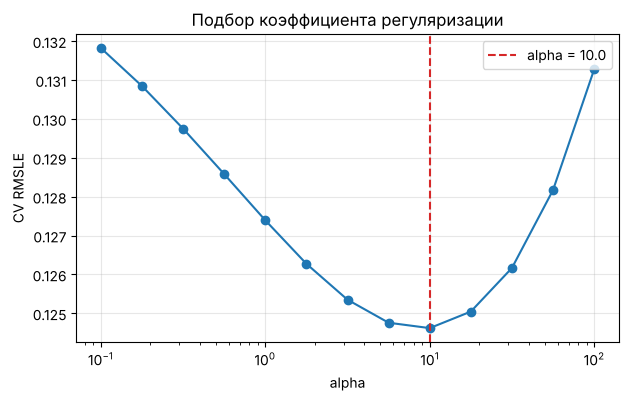

In [19]:
alphas = param_grid["model__alpha"]
cv_rmsle = -search.cv_results_["mean_test_score"]

plt.figure(figsize=(7, 4))
plt.semilogx(alphas, cv_rmsle, marker="o")
plt.axvline(best_alpha, color="tab:red", linestyle="--", label=f"alpha = {best_alpha:.1f}")
plt.xlabel("alpha")
plt.ylabel("CV RMSLE")
plt.title("Подбор коэффициента регуляризации")
plt.legend()
plt.show()

Кривая плоская возле минимума: качество слабо зависит от точного значения `alpha`. При слишком слабой регуляризации модель переобучается (много one-hot признаков), при слишком сильной недообучается.

In [20]:
final_model = make_ultimate_pipeline(alpha=best_alpha)
evaluate(f"Итоговый пайплайн (alpha = {best_alpha:.1f})", final_model)
pd.DataFrame(results).round(4).tail(1)

,model,CV RMSLE,CV std,test MAE,test RMSLE
9,Итоговый пайплайн (alpha = 10.0),0.1246,0.0126,14668.4033,0.1323


## 10. Линейная регрессия с нуля (SGD)

Чтобы разобраться, как обучается линейная модель, реализуем её сами. Модель предсказывает $\widehat{y}(x) = x^\top W + b$ и минимизирует

$$
F(W, b) = \frac{1}{n}\sum_{i=1}^{n}\left(y_i - x_i^\top W - b\right)^2 + \lambda \|W\|_2^2 \longrightarrow \min_{W,b},
$$

причём свободный член $b$ не регуляризуется. Градиент считается на случайном мини-батче:

$$
\nabla_W = -\frac{2}{B} X_B^\top (y_B - X_B W - b) + 2\lambda W, \qquad
\nabla_b = -\frac{2}{B} \sum (y_B - X_B W - b).
$$

Обучение останавливается, когда норма изменения весов за шаг меньше `delta_converged`, либо по достижении `max_steps`.

In [21]:
class SGDLinearRegressor(RegressorMixin, BaseEstimator):
    """Линейная регрессия с L2-регуляризацией, обученная мини-батч SGD."""

    def __init__(self, lr=0.01, regularization=0.1, delta_converged=1e-4,
                 max_steps=5000, batch_size=64, random_state=None):
        self.lr = lr
        self.regularization = regularization
        self.delta_converged = delta_converged
        self.max_steps = max_steps
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        rng = np.random.default_rng(self.random_state)
        n_objects, n_features = X.shape
        batch_size = min(self.batch_size, n_objects)

        self.W_ = np.zeros(n_features)
        self.b_ = 0.0

        for step in range(1, self.max_steps + 1):
            idx = rng.choice(n_objects, size=batch_size, replace=False)
            X_batch, y_batch = X[idx], y[idx]

            residuals = y_batch - (X_batch @ self.W_ + self.b_)
            grad_W = -2 / batch_size * (X_batch.T @ residuals) + 2 * self.regularization * self.W_
            grad_b = -2 / batch_size * residuals.sum()

            W_new = self.W_ - self.lr * grad_W
            b_new = self.b_ - self.lr * grad_b

            converged = np.linalg.norm(W_new - self.W_) < self.delta_converged
            self.W_, self.b_ = W_new, b_new
            if converged:
                break

        self.n_steps_ = step
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.W_ + self.b_

Гиперпараметры (`lr`, `regularization`) подбираем на **валидационной части train**, а тест не трогаем. Признаки те же, что у бейзлайна: числовые, стандартизованные.

In [22]:
prep = BaseDataPreprocessor(numeric_columns).fit(X_train)
A_train, A_test = prep.transform(X_train), prep.transform(X_test)

A_fit, A_val, y_fit, y_val = train_test_split(A_train, y_train, test_size=0.25, random_state=SEED)

rows = []
for lr in [0.003, 0.01, 0.03]:
    for reg in [0.01, 0.1, 1.0]:
        model = SGDLinearRegressor(lr=lr, regularization=reg, max_steps=2000,
                                   batch_size=64, random_state=0).fit(A_fit, y_fit)
        rows.append({"lr": lr, "regularization": reg,
                     "val MAE": mean_absolute_error(y_val, model.predict(A_val))})

grid = pd.DataFrame(rows)
print(grid.pivot(index="lr", columns="regularization", values="val MAE").round(0).to_string())
best = grid.loc[grid["val MAE"].idxmin()]
print(f"\nЛучшие параметры: lr = {best['lr']}, regularization = {best['regularization']}")

regularization     0.01     0.10     1.00
lr                                       
0.003           20798.0  21041.0  22880.0
0.010           21228.0  21595.0  22920.0
0.030           24205.0  24547.0  24203.0

Лучшие параметры: lr = 0.003, regularization = 0.01


In [23]:
sgd = SGDLinearRegressor(lr=best["lr"], regularization=best["regularization"],
                         max_steps=2000, batch_size=64, random_state=0).fit(A_train, y_train)
pred_sgd = sgd.predict(A_test)

# Аналитическое решение для той же функции потерь: Ridge с alpha = n * lambda
n_train = len(A_train)
ridge = Ridge(alpha=n_train * best["regularization"]).fit(A_train, y_train)
pred_ridge = ridge.predict(A_test)

print(f"Шагов SGD: {sgd.n_steps_}")
print(f"SGD:   MAE = {mean_absolute_error(y_test, pred_sgd):,.0f}, RMSLE = {rmsle(y_test, pred_sgd):.4f}")
print(f"Ridge: MAE = {mean_absolute_error(y_test, pred_ridge):,.0f}, RMSLE = {rmsle(y_test, pred_ridge):.4f}")
print(f"Корреляция весов SGD и Ridge: {np.corrcoef(sgd.W_, ridge.coef_)[0, 1]:.3f}")

results.append({
    "model": "SGD с нуля (числовые признаки)", "CV RMSLE": np.nan, "CV std": np.nan,
    "test MAE": mean_absolute_error(y_test, pred_sgd), "test RMSLE": rmsle(y_test, pred_sgd),
})

Шагов SGD: 2000
SGD:   MAE = 23,870, RMSLE = 0.1937
Ridge: MAE = 23,812, RMSLE = 0.1943
Корреляция весов SGD и Ridge: 0.997


SGD доходит до качества, близкого к аналитическому решению: веса почти совпадают, а метрики отличаются незначительно. Критерий остановки по `delta_converged` на шумных мини-батчах практически не срабатывает, поэтому реальное ограничение задаёт `max_steps`. В `Ridge` в качестве коэффициента нужно брать $n \cdot \lambda$, потому что в нашей функции потерь ошибка усредняется по объектам, а в `sklearn` суммируется.

## 11. Итоги

In [24]:
summary = pd.DataFrame(results).round(4)
summary

,model,CV RMSLE,CV std,test MAE,test RMSLE
0,Linear Regression (числовые признаки),0.1975,0.0053,23822.6965,0.1950
1,Ridge,0.1974,0.0053,23821.9778,0.1950
2,Ridge + пропуски и расстояние до центра,0.1960,0.0055,23652.8269,0.1947
3,Ridge + логарифм признаков,0.3959,0.2141,27285.7087,0.4978
4,Exp-Ridge (числовые признаки),0.1651,0.0139,26818.6998,0.2160
5,Exp-Ridge + пропуски и расстояние,0.1640,0.0140,27295.2548,0.2170
6,"Exp-Ridge + пропуски, расстояние, логарифм при...",0.1635,0.0109,21539.2869,0.1707
7,Exp-Ridge + 4 категориальных признака,0.1390,0.0095,17282.1814,0.1491
8,Exp-Ridge + все категориальные признаки,0.1274,0.0127,14888.3089,0.1358
9,Итоговый пайплайн (alpha = 10.0),0.1246,0.0126,14668.4033,0.1323


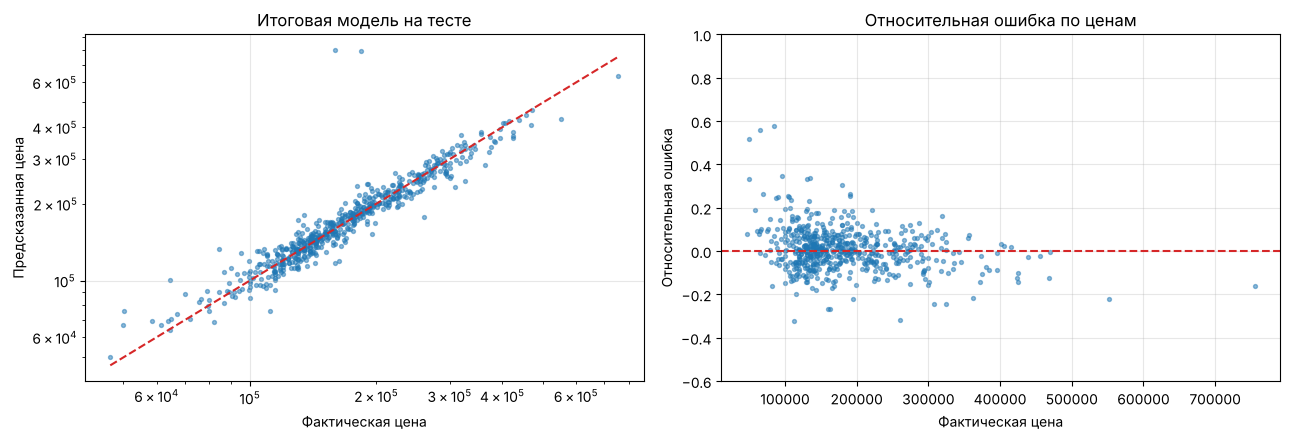

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

pred_final = final_model.predict(X_test)
axes[0].scatter(y_test, pred_final, s=8, alpha=0.5)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, color="tab:red", linestyle="--")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Фактическая цена")
axes[0].set_ylabel("Предсказанная цена")
axes[0].set_title("Итоговая модель на тесте")

rel_error = (pred_final - y_test) / y_test
axes[1].scatter(y_test, rel_error, s=8, alpha=0.5)
axes[1].axhline(0, color="tab:red", linestyle="--")
axes[1].set_xlabel("Фактическая цена")
axes[1].set_ylabel("Относительная ошибка")
axes[1].set_title("Относительная ошибка по ценам")
axes[1].set_ylim(-0.6, 1.0)
plt.tight_layout()
plt.show()

In [26]:
big_errors = np.where(np.abs(rel_error) > 1)[0]
print(f"Домов с относительной ошибкой больше 100%: {len(big_errors)} из {len(y_test)}")
for i in big_errors:
    house = X_test.iloc[i]
    print(f"  Gr_Liv_Area = {house['Gr_Liv_Area']}, Sale_Condition = {house['Sale_Condition']}, "
          f"факт {y_test[i]:,.0f} $, предсказание {pred_final[i]:,.0f} $")

mask = np.abs(rel_error) <= 1
print(f"Доля предсказаний с ошибкой не больше 20%: {(np.abs(rel_error) <= 0.2).mean():.1%}")
print(f"\nRMSLE на тесте: {rmsle(y_test, pred_final):.4f} со всеми домами, "
      f"{rmsle(y_test[mask], pred_final[mask]):.4f} без них")

Домов с относительной ошибкой больше 100%: 2 из 586
  Gr_Liv_Area = 5095, Sale_Condition = Partial, факт 183,850 $, предсказание 792,557 $
  Gr_Liv_Area = 5642, Sale_Condition = Partial, факт 160,000 $, предсказание 801,312 $
Доля предсказаний с ошибкой не больше 20%: 95.2%

RMSLE на тесте: 0.1323 со всеми домами, 0.0973 без них


Модель сильно завысила цену двух домов: у них огромная жилая площадь (больше 5 000 кв. футов), но продажа с типом `Partial` (недостроенный дом на момент оценки) и низкая итоговая цена. Это известные аномалии этого набора данных. Линейная модель честно экстраполирует «огромная площадь → очень дорого». Без этих двух объектов RMSLE на тесте падает с 0.132 до 0.097, то есть выбросы заметно влияют на метрику. Для остальных домов ошибка небольшая: около 95% предсказаний отличаются от фактической цены не более чем на 20%.

Ниже показаны признаки с наибольшими по модулю коэффициентами. Так как признаки стандартизованы, а таргет логарифмирован, коэффициент примерно равен относительному изменению цены при росте признака на одно стандартное отклонение. Результаты интуитивны: жилая площадь, общее качество и состояние дома повышают цену, а плохое качество, плохое состояние и нетипичные условия продажи понижают.

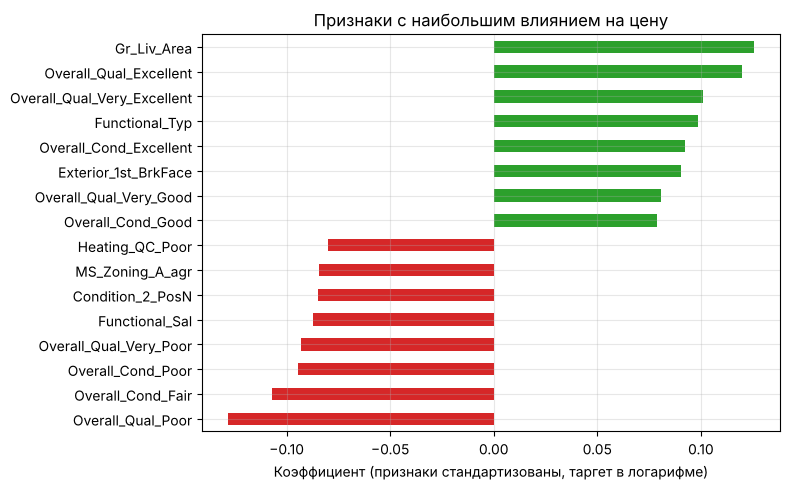

In [27]:
names = final_model.named_steps["preprocessor"].get_feature_names_out()
coefs = pd.Series(final_model.named_steps["model"].model_.coef_, index=names).sort_values()

top = pd.concat([coefs.head(8), coefs.tail(8)])
plt.figure(figsize=(8, 5))
top.plot(kind="barh", color=["tab:red" if v < 0 else "tab:green" for v in top])
plt.xlabel("Коэффициент (признаки стандартизованы, таргет в логарифме)")
plt.title("Признаки с наибольшим влиянием на цену")
plt.tight_layout()
plt.show()

## Выводы

1. **Метрика.** Для цен подходит RMSLE: она измеряет относительную ошибку, а MAE даёт слишком большой вес дорогим домам.
2. **Логарифм таргета** — самое важное решение для линейной модели. Он снижает кросс-валидационную ошибку, делает предсказания всегда положительными и не даёт отдельным экстремальным объектам разрушить метрику.
3. **Feature engineering** (замена скрытых пропусков, расстояние до центра, логарифм скошенных признаков) даёт небольшой выигрыш сам по себе, но в паре с логарифмом таргета работает заметно лучше.
4. **Категориальные признаки** дают наибольший прирост: переход от числовых признаков к one-hot по всем категориям снижает RMSLE по кросс-валидации с 0.164 до 0.127 (c подбором `alpha` до 0.125).
5. **Валидация.** Оценка на одном hold-out разбиении может противоречить кросс-валидации, поэтому решения принимались по CV, а тест использовался один раз для финальной оценки.
6. **Итоговая модель** (one-hot по всем категориям, логарифм таргета, `Ridge` с подобранным `alpha`) достигает CV RMSLE 0.125 и RMSLE 0.132 на тесте, а средняя абсолютная ошибка составляет около 14 700 $ против 23 800 $ у бейзлайна.
7. **Своя реализация SGD** сходится к решению, близкому к аналитическому, что подтверждает корректность градиентов и регуляризации.

## Что можно улучшить

- Убрать выбросы (как минимум два дома с площадью больше 5 000 кв. футов, найденные выше) и проверить влияние на метрику.
- Закодировать порядковые признаки качества (`Excellent` > `Good` > `Typical` ...) числами, а не one-hot.
- Добавить взаимодействия признаков (например, площадь × качество) и полиномиальные признаки.
- Попробовать `Lasso` или `ElasticNet` для отбора признаков.
- Сравнить с градиентным бустингом на тех же признаках.